# Phase 1 — Exploratory Data Analysis

**Purpose.** Every parameter in the frozen protocol (`data.py`) is a choice, and a choice
that cannot be defended is a choice that will be attacked. This notebook establishes the
empirical basis for each one: the positive threshold, the chronological split and its
tie-break, the history cap, the candidate filter, the activity bands, and the decision to
report beyond-accuracy metrics as first-class results rather than footnotes.

It also motivates the model ladder itself. The central claim of a factorization machine is
that *second-order interactions between features carry signal that first-order terms miss*.
That is an empirical claim about this dataset, and Section 7 tests it directly — before any
model is fitted.

Where a section ends in a protocol decision, it is marked **→ Protocol**.

In [1]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import scipy.sparse as sp

warnings.filterwarnings("ignore", category=FutureWarning)
sys.path.insert(0, ".")
import data as D

# House style: one accent colour, muted supporting palette, no chartjunk.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.fontsize": 8.5,
    "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": "0.75",
    "figure.facecolor": "white",
})
ACCENT, MUTED, WARN = "#2B6CB0", "#A0AEC0", "#C05621"

def pct(x, d=1): return f"{100*x:.{d}f}%"
def thousands(ax, axis="y"):
    getattr(ax, f"{axis}axis").set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))

ratings_raw, movies_raw, users_raw = D.load_raw()
print(f"ratings  {ratings_raw.shape}   {list(ratings_raw.columns)}")
print(f"movies   {movies_raw.shape}   {list(movies_raw.columns)}")
print(f"users    {users_raw.shape}   {list(users_raw.columns)}")
print()
print(ratings_raw.head(3).to_string(index=False))
print()
print(movies_raw.head(3).to_string(index=False))
print()
print(users_raw.head(3).to_string(index=False))

ratings  (1000209, 4)   ['UserID', 'MovieID', 'Rating', 'Timestamp']
movies   (3883, 3)   ['MovieID', 'Title', 'Genre']
users    (6040, 5)   ['UserID', 'Gender', 'Age', 'Occupation', 'Zip']

 UserID  MovieID  Rating  Timestamp
      1     1193       5  978300760
      1      661       3  978302109
      1      914       3  978301968

 MovieID                   Title                        Genre
       1        Toy Story (1995)  Animation|Children's|Comedy
       2          Jumanji (1995) Adventure|Children's|Fantasy
       3 Grumpier Old Men (1995)               Comedy|Romance

 UserID Gender  Age  Occupation   Zip
      1      F    1          10 48067
      2      M   56          16 70072
      3      M   25          15 55117


---
## 1. What the data is

MovieLens-1M is a *curated* dataset, not a log. GroupLens filtered it to users with at
least 20 ratings. That filtering is convenient and it is also the first thing that makes
results here optimistic relative to a real system, where the median user has rated
approximately nothing. It is worth measuring precisely, because it determines what "cold
start" can even mean in this project.

In [2]:
n_ratings = len(ratings_raw)
n_users = users_raw["UserID"].nunique()
n_catalogue = movies_raw["MovieID"].nunique()
n_rated = ratings_raw["MovieID"].nunique()

print("INTEGRITY")
print(f"  duplicate (user, item) pairs        {ratings_raw.duplicated(['UserID','MovieID']).sum():>10,}")
print(f"  ratings referencing unknown movie   {(~ratings_raw['MovieID'].isin(movies_raw['MovieID'])).sum():>10,}")
print(f"  ratings referencing unknown user    {(~ratings_raw['UserID'].isin(users_raw['UserID'])).sum():>10,}")
print(f"  null values anywhere                {int(ratings_raw.isna().sum().sum() + movies_raw.isna().sum().sum() + users_raw.isna().sum().sum()):>10,}")
print(f"  rating values observed              {sorted(ratings_raw['Rating'].unique().tolist())}")

print("\nSHAPE")
print(f"  ratings                             {n_ratings:>10,}")
print(f"  users                               {n_users:>10,}")
print(f"  movies in catalogue                 {n_catalogue:>10,}")
print(f"  movies with >=1 rating              {n_rated:>10,}")
print(f"  movies NEVER rated                  {n_catalogue - n_rated:>10,}  ({pct((n_catalogue-n_rated)/n_catalogue)} of catalogue)")
print(f"  density of the user x item matrix   {pct(n_ratings/(n_users*n_catalogue), 2):>10}")

print("\nMINIMUM ACTIVITY (the GroupLens >=20 filter)")
per_user = ratings_raw.groupby("UserID").size()
print(f"  min ratings per user                {per_user.min():>10,}")
print(f"  users with exactly 20               {(per_user == 20).sum():>10,}")
print(f"  => there is no genuinely cold user in this dataset.")
print(f"     'Cold' here can only mean relatively-light, which is a weaker claim")
print(f"     and must be stated as such whenever cold-start results are reported.")

INTEGRITY
  duplicate (user, item) pairs                 0
  ratings referencing unknown movie            0
  ratings referencing unknown user             0
  null values anywhere                         0
  rating values observed              [1, 2, 3, 4, 5]

SHAPE
  ratings                              1,000,209
  users                                    6,040
  movies in catalogue                      3,883
  movies with >=1 rating                   3,706
  movies NEVER rated                         177  (4.6% of catalogue)
  density of the user x item matrix        4.26%

MINIMUM ACTIVITY (the GroupLens >=20 filter)
  min ratings per user                        20
  users with exactly 20                       86
  => there is no genuinely cold user in this dataset.
     'Cold' here can only mean relatively-light, which is a weaker claim
     and must be stated as such whenever cold-start results are reported.


---
## 2. The ratings themselves — constructing a label

The protocol turns a 1–5 rating into a binary label at `rating >= 4`. Three things need
justifying: that binarising at all is reasonable, that 4 is the right cut, and what the
resulting negative class actually contains.

The deeper issue this section surfaces is **selection bias**. A rating exists only where a
user chose to watch a film, and people largely watch films they expect to enjoy. The
observed rating distribution is therefore not a sample of preferences — it is a sample of
preferences *filtered through the user's own prior*. Every model here inherits that bias,
and the regression arm of the objective study inherits it most severely, because it can
only be trained where a rating exists.

In [3]:
r = ratings_raw["Rating"]
dist = r.value_counts().sort_index()

print("RATING DISTRIBUTION")
for v, c in dist.items():
    print(f"  {v}  {c:>9,}  {pct(c/len(r)):>7}  {'#'*int(60*c/dist.max())}")
print(f"\n  mean {r.mean():.3f}   median {r.median():.0f}   std {r.std():.3f}")

print("\nCANDIDATE THRESHOLDS")
for t in (3, 4, 5):
    p = (r >= t).mean()
    print(f"  rating >= {t}   positive rate {pct(p):>7}   class ratio {p/(1-p):>6.2f} : 1")

print("\nSELECTION BIAS (MNAR)")
print(f"  share of ratings that are 1 or 2    {pct((r <= 2).mean()):>8}")
print(f"  share that are 4 or 5               {pct((r >= 4).mean()):>8}")
print(f"  If ratings sampled preferences at random we would expect far more low")
print(f"  scores: users rate what they chose to watch, having already screened out")
print(f"  what they expected to dislike. The negative class is therefore scarce and")
print(f"  unrepresentative -- which is precisely why sampled negatives exist.")

print("\nRATER BIAS: is a fixed global threshold fair to every user?")
um = ratings_raw.groupby("UserID")["Rating"].mean()
print(f"  per-user mean rating: min {um.min():.2f}  p10 {um.quantile(.10):.2f}  "
      f"median {um.median():.2f}  p90 {um.quantile(.90):.2f}  max {um.max():.2f}")
harsh = (um < 3.0).sum(); lenient = (um > 4.3).sum()
print(f"  users averaging < 3.0 ('harsh')     {harsh:>5,}  ({pct(harsh/len(um))})")
print(f"  users averaging > 4.3 ('lenient')   {lenient:>5,}  ({pct(lenient/len(um))})")
frac_pos = ratings_raw.assign(p=r >= 4).groupby("UserID")["p"].mean()
print(f"  per-user positive rate at >=4: p10 {frac_pos.quantile(.10):.2f}  "
      f"median {frac_pos.median():.2f}  p90 {frac_pos.quantile(.90):.2f}")
print(f"  {(frac_pos < 0.15).sum()} users would have almost no positives, and "
      f"{(frac_pos > 0.90).sum()} almost no negatives.")

RATING DISTRIBUTION
  1     56,174     5.6%  #########
  2    107,557    10.8%  ##################
  3    261,197    26.1%  ############################################
  4    348,971    34.9%  ############################################################
  5    226,310    22.6%  ######################################

  mean 3.582   median 4   std 1.117

CANDIDATE THRESHOLDS
  rating >= 3   positive rate   83.6%   class ratio   5.11 : 1
  rating >= 4   positive rate   57.5%   class ratio   1.35 : 1
  rating >= 5   positive rate   22.6%   class ratio   0.29 : 1

SELECTION BIAS (MNAR)
  share of ratings that are 1 or 2       16.4%
  share that are 4 or 5                  57.5%
  If ratings sampled preferences at random we would expect far more low
  scores: users rate what they chose to watch, having already screened out
  what they expected to dislike. The negative class is therefore scarce and
  unrepresentative -- which is precisely why sampled negatives exist.

RATER BIAS: is a fixed

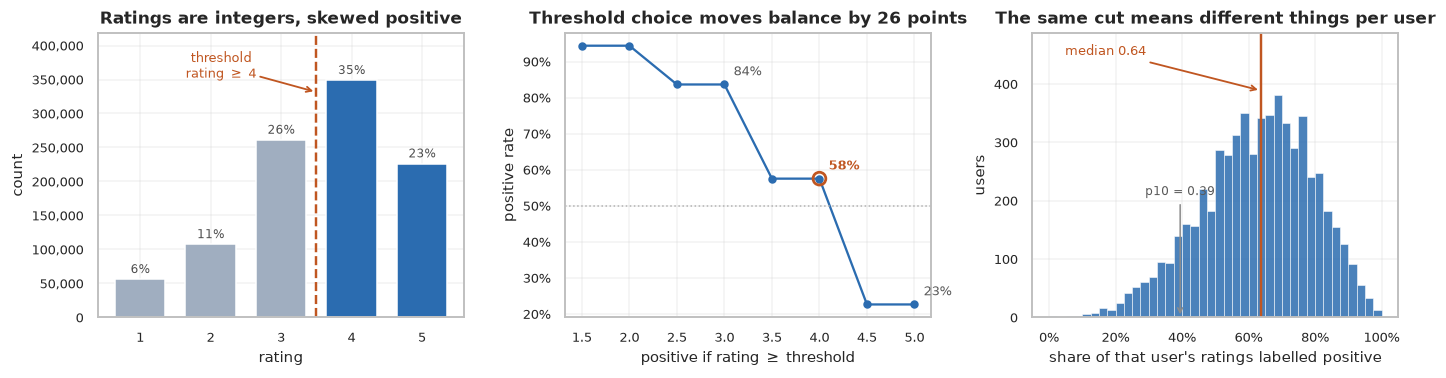

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

ax = axes[0]
cols = [MUTED if v < 4 else ACCENT for v in dist.index]
ax.bar(dist.index, dist.values, color=cols, edgecolor="white", width=0.72)
ax.axvline(3.5, color=WARN, ls="--", lw=1.6)
ax.annotate("threshold\nrating $\\geq$ 4", xy=(3.5, dist.max()*0.95), xytext=(2.15, dist.max()*1.06),
            color=WARN, fontsize=8.5, ha="center", va="center",
            arrowprops=dict(arrowstyle="->", color=WARN, lw=1.2, shrinkA=0, shrinkB=2))
ax.set_title("Ratings are integers, skewed positive")
ax.set_xlabel("rating"); ax.set_ylabel("count"); thousands(ax)
for v, c in dist.items():
    ax.text(v, c + 9000, pct(c/len(r), 0), ha="center", fontsize=8, color="0.3")
ax.set_ylim(0, dist.max()*1.20)

ax = axes[1]
ths = np.arange(1.5, 5.1, 0.5)
pr = [(r >= t).mean() for t in ths]
ax.plot(ths, pr, "-o", color=ACCENT, ms=4.5)
ax.axhline(0.5, color="0.7", lw=1, ls=":")
for t, p in zip(ths, pr):
    if t in (3.0, 4.0, 5.0):
        ax.annotate(pct(p, 0), (t, p), textcoords="offset points", xytext=(6, 6),
                    fontsize=8.5, color=WARN if t == 4 else "0.35",
                    fontweight="bold" if t == 4 else "normal")
ax.scatter([4], [(r >= 4).mean()], s=70, facecolor="none", edgecolor=WARN, lw=1.8, zorder=5)
ax.set_title("Threshold choice moves balance by 26 points")
ax.set_xlabel("positive if rating $\\geq$ threshold"); ax.set_ylabel("positive rate")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))

ax = axes[2]
cnts, _, _ = ax.hist(frac_pos, bins=40, color=ACCENT, alpha=0.85, edgecolor="white", lw=0.4)
ax.set_ylim(0, cnts.max()*1.28)
ax.axvline(frac_pos.median(), color=WARN, lw=1.6)
ax.annotate(f"median {frac_pos.median():.2f}", xy=(frac_pos.median(), cnts.max()*1.02),
            xytext=(0.17, cnts.max()*1.18), color=WARN, fontsize=8.5, ha="center",
            arrowprops=dict(arrowstyle="->", color=WARN, lw=1.2))
ax.annotate("p10 = 0.39", xy=(frac_pos.quantile(.10), 0), xytext=(frac_pos.quantile(.10), cnts.max()*0.55),
            color="0.35", fontsize=8, ha="center",
            arrowprops=dict(arrowstyle="->", color="0.55", lw=1))
ax.set_title("The same cut means different things per user")
ax.set_xlabel("share of that user's ratings labelled positive"); ax.set_ylabel("users")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))

plt.tight_layout(); plt.show()

**→ Protocol.** `pos_threshold = 4`.

- **Binarise rather than regress.** The product is a ranked list, so the model must be able
  to score items the user never rated, and a rating target exists only where a rating does.
  The regression arm is retained in the objective study precisely to quantify what this
  costs, not because it is the natural framing.
- **Cut at 4, not 3.** `>= 3` labels 83.6% of interactions positive — a 5:1 imbalance in
  which "positive" includes the indifferent middle of the scale. `>= 4` gives 57.5%, close
  enough to balanced that AUC and logloss stay interpretable without reweighting, and it
  matches the ordinary reading of a 5-point scale where 3 is lukewarm.
- **The negative class is heterogeneous, deliberately.** At `>= 4` it contains ratings of
  1–3: films the user *chose to watch* and was unenthusiastic about. That is a different
  object from a film the user never encountered. The protocol keeps both available as
  separate sampling policies rather than silently merging them, and the objective study
  measures which makes a better negative.
- **A fixed global cut is known to be unfair and accepted anyway.** Per-user positive rates
  run from 0.39 at the 10th percentile to 0.83 at the 90th; 22 users end up with almost no
  positives and 181 with almost no negatives. Per-user centring (`rating >` that user's own
  mean) would absorb this, and is registered as a sub-ablation rather than adopted by
  default, because a user-relative label makes the classification metrics incomparable
  across users.

---
## 3. Users: how much they rate, and who they are

Two questions. First, how unevenly is activity distributed — this sets the boundaries for
the cold/warm/heavy slices, and determines how badly an aggregate metric will be dominated
by a minority of accounts. Second, do the demographic fields carry any signal at all —
this decides whether the `user_demo` feature block earns its place, or is 30 columns of
noise that a factorization machine will dutifully fit anyway.

In [5]:
per_user = ratings_raw.groupby("UserID").size()
q = per_user.quantile([.10, .25, .50, .75, .90, .99])

print("ACTIVITY PER USER (all splits)")
print(f"  min {per_user.min()}   p10 {q[.10]:.0f}   p25 {q[.25]:.0f}   median {q[.50]:.0f}   "
      f"p75 {q[.75]:.0f}   p90 {q[.90]:.0f}   p99 {q[.99]:.0f}   max {per_user.max()}")
print(f"  mean {per_user.mean():.1f}  vs median {per_user.median():.0f}  "
      f"-> heavily right-skewed")

top10 = per_user.nlargest(int(0.10*len(per_user))).sum()
bot50 = per_user.nsmallest(int(0.50*len(per_user))).sum()
print(f"\n  the most active 10% of users produce {pct(top10/len(ratings_raw))} of all ratings")
print(f"  the least active 50% of users produce {pct(bot50/len(ratings_raw))} of all ratings")
print(f"  => an unweighted mean over interactions is a statement about heavy users;")
print(f"     an unweighted mean over users is a different statement. This project")
print(f"     averages over USERS, and slices, so neither hides the other.")

print("\nWHO THEY ARE")
g = users_raw["Gender"].value_counts()
print(f"  gender      " + "   ".join(f"{k}: {v:,} ({pct(v/len(users_raw),0)})" for k, v in g.items()))
age = users_raw["Age"].map(D.AGE_MAP).value_counts()
order = [D.AGE_MAP[k] for k in sorted(D.AGE_MAP)]
print("  age groups  " + "  ".join(f"{k}:{age.get(k,0):,}" for k in order))
occ = users_raw["Occupation"].value_counts()
print(f"  occupations {len(occ)} distinct, largest {occ.iloc[0]:,} users, smallest {occ.iloc[-1]:,}")

print("\nIS THERE SIGNAL IN DEMOGRAPHICS?  (positive rate = share of that group's ratings >= 4)")
merged = ratings_raw.merge(users_raw, on="UserID")
merged["pos"] = (merged["Rating"] >= 4).astype(int)
base = merged["pos"].mean()
print(f"  population baseline positive rate: {pct(base)}\n")
for col, label in (("Gender", "gender"), ("Age", "age")):
    gr = merged.groupby(col)["pos"].agg(["mean", "size"])
    if col == "Age":
        gr.index = [D.AGE_MAP[i] for i in gr.index]
    print(f"  by {label}:")
    for k, row in gr.iterrows():
        print(f"    {str(k):<12} {pct(row['mean']):>7}   ({row['size']:>7,.0f} ratings)   "
              f"{100*(row['mean']-base):+.1f} pts")
occ_g = merged.groupby("Occupation")["pos"].agg(["mean", "size"]).sort_values("mean")
print(f"\n  by occupation: range {pct(occ_g['mean'].min())} to {pct(occ_g['mean'].max())}  "
      f"(spread {100*(occ_g['mean'].max()-occ_g['mean'].min()):.1f} pts across {len(occ_g)} groups)")
print(f"    lowest  {occ_g.index[0]:>3}: {pct(occ_g['mean'].iloc[0])}   "
      f"highest {occ_g.index[-1]:>3}: {pct(occ_g['mean'].iloc[-1])}")

ACTIVITY PER USER (all splits)
  min 20   p10 27   p25 44   median 96   p75 208   p90 400   p99 907   max 2314
  mean 165.6  vs median 96  -> heavily right-skewed

  the most active 10% of users produce 38.1% of all ratings
  the least active 50% of users produce 14.6% of all ratings
  => an unweighted mean over interactions is a statement about heavy users;
     an unweighted mean over users is a different statement. This project
     averages over USERS, and slices, so neither hides the other.

WHO THEY ARE
  gender      M: 4,331 (72%)   F: 1,709 (28%)
  age groups  Under 18:222  18-24:1,103  25-34:2,096  35-44:1,193  45-49:550  50-55:496  56+:380
  occupations 21 distinct, largest 759 users, smallest 17

IS THERE SIGNAL IN DEMOGRAPHICS?  (positive rate = share of that group's ratings >= 4)
  population baseline positive rate: 57.5%

  by gender:
    F              59.1%   (246,440 ratings)   +1.6 pts
    M              57.0%   (753,769 ratings)   -0.5 pts
  by age:
    Under 18     

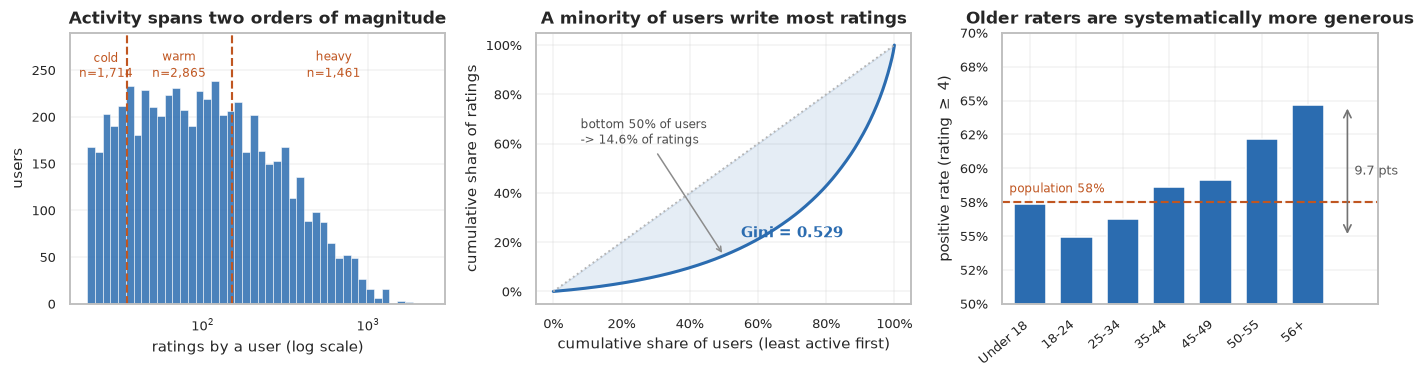

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

ax = axes[0]
ax.hist(per_user, bins=np.logspace(np.log10(20), np.log10(per_user.max()), 45),
        color=ACCENT, alpha=0.85, edgecolor="white", lw=0.4)
ax.set_xscale("log")
top = ax.get_ylim()[1]*1.16
ax.set_ylim(0, top)
for edge in (35, 150):
    ax.axvline(edge, color=WARN, ls="--", lw=1.4)
for cx, nm, n in ((26, "cold", 1714), (72, "warm", 2865), (620, "heavy", 1461)):
    ax.text(cx, top*0.94, f"{nm}\nn={n:,}", color=WARN, fontsize=8,
            ha="center", va="top", linespacing=1.3)
ax.set_title("Activity spans two orders of magnitude")
ax.set_xlabel("ratings by a user (log scale)"); ax.set_ylabel("users")

ax = axes[1]
s = np.sort(per_user.values)
cum = np.cumsum(s) / s.sum()
x = np.arange(1, len(s)+1) / len(s)
ax.plot(x, cum, color=ACCENT, lw=2)
ax.plot([0, 1], [0, 1], color="0.7", ls=":", lw=1.2)
ax.fill_between(x, cum, x, color=ACCENT, alpha=0.12)
g_users = (2*np.arange(1, len(s)+1) - len(s) - 1).dot(s) / (len(s)*s.sum())
ax.annotate(f"Gini = {g_users:.3f}", xy=(0.55, 0.22), fontsize=9.5, color=ACCENT, fontweight="bold")
ax.annotate("bottom 50% of users\n-> 14.6% of ratings", xy=(0.5, cum[len(s)//2]),
            xytext=(0.08, 0.60), fontsize=8, color="0.3",
            arrowprops=dict(arrowstyle="->", color="0.55", lw=1))
ax.set_title("A minority of users write most ratings")
ax.set_xlabel("cumulative share of users (least active first)")
ax.set_ylabel("cumulative share of ratings")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))

ax = axes[2]
ag = merged.groupby("Age")["pos"].mean()
ag.index = [D.AGE_MAP[i] for i in ag.index]
ag = ag.reindex(order)
bars = ax.bar(range(len(ag)), ag.values, color=ACCENT, edgecolor="white", width=0.7)
ax.set_ylim(0.50, 0.70)
ax.axhline(base, color=WARN, ls="--", lw=1.4)
ax.text(-0.45, base + 0.007, f"population {pct(base,0)}", color=WARN, fontsize=8, ha="left")
ax.set_xlim(-0.6, 7.5)
ax.annotate("", xy=(6.85, ag.iloc[-1]), xytext=(6.85, ag.iloc[1]),
            arrowprops=dict(arrowstyle="<->", color="0.45", lw=1.1))
ax.text(7.0, (ag.iloc[-1] + ag.iloc[1]) / 2, "9.7 pts", fontsize=8.5,
        color="0.35", va="center", ha="left")
ax.set_xticks(range(len(ag))); ax.set_xticklabels(ag.index, rotation=40, ha="right")
ax.set_title("Older raters are systematically more generous")
ax.set_ylabel("positive rate (rating $\\geq$ 4)")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))

plt.tight_layout(); plt.show()

**→ Protocol.** Activity bands at **<35 / 35–150 / ≥150 training interactions**, and the
`user_demo` block is **kept**.

- **Bands are set from the quartiles of training count, not from round numbers.** Training
  counts run 10–1,619 with quartiles 31/67/145, so these edges give 1,741 / 2,845 / 1,454
  users — three bands that are each large enough to have a stable mean.
- **Bands must use the *training* count, not the total.** MovieLens guarantees ≥20 ratings
  per user overall, so a band defined on total activity is empty below 20 and the cold
  segment vanishes exactly where it matters.
- **Metrics average over users, not over interactions.** The top 10% of users produce 38.1%
  of all ratings; an interaction-weighted mean would be a statement about heavy users
  wearing the costume of a global result.
- **Demographics carry real but modest first-order signal.** Positive rate rises
  monotonically with age, from 54.9% (18–24) to 64.6% (56+) — a ~10-point spread that is
  far too large to be noise at these sample sizes. Occupation spreads 13.3 points, though
  its smallest group has only 17 users and will need regularisation rather than trust.
  Gender is weak (≈2 points) and is kept mainly as an interaction partner rather than for
  its main effect.
- **Caveat that limits what any of this proves.** These are *main effects*: they shift a
  user's baseline generosity, which a first-order model captures perfectly well. They are
  not evidence for second-order interactions, and must not be cited as such. Section 7
  tests that separately.

---
## 4. Items: the long tail, and why popularity is hard to beat

From here on the analysis uses the protocol object itself, so that every statistic is
computed on exactly the data a model will see. In particular **popularity is counted on the
training split only** — using full-data counts would leak the test period into the very
baseline the benchmark is measured against.

This section decides three things: whether the `min_item_ratings = 50` candidate filter is
defensible, whether catalogue coverage and Gini deserve to be first-class metrics rather
than footnotes, and why the damped mean is the baseline that matters rather than a raw mean
rating.

In [7]:
ds = D.build()
train = ds.split_rows("train")
cnt = ds.item_train_count                      # train-only popularity
rated = cnt > 0

print("\nITEM POPULARITY (training split)")
nz = cnt[rated]
print(f"  items with >=1 training rating      {rated.sum():>6,} of {ds.n_items:,}")
print(f"  items with ZERO training ratings    {(~rated).sum():>6,}  "
      f"({pct((~rated).sum()/ds.n_items)} of catalogue -- unrecommendable by any")
print(f"                                              collaborative model, cold by construction)")
print(f"  ratings per item: p25 {np.percentile(nz,25):.0f}  median {np.percentile(nz,50):.0f}  "
      f"p75 {np.percentile(nz,75):.0f}  p95 {np.percentile(nz,95):.0f}  max {nz.max():,}")

srt = np.sort(cnt)[::-1]
tot = srt.sum()
for f in (0.01, 0.05, 0.10, 0.20):
    k = int(f*ds.n_items)
    print(f"  top {pct(f,0):>4} of catalogue ({k:>4} items) -> {pct(srt[:k].sum()/tot):>6} of interactions")
g_items = (2*np.arange(1, ds.n_items+1) - ds.n_items - 1).dot(np.sort(cnt)) / (ds.n_items*tot)
print(f"  Gini of item popularity: {g_items:.3f}")

print("\nTHE CANDIDATE FILTER (min_item_ratings = 50)")
est = cnt >= ds.cfg.min_item_ratings
print(f"  items kept                          {est.sum():>6,}  ({pct(est.sum()/ds.n_items)} of catalogue)")
print(f"  items removed                       {(~est).sum():>6,}  ({pct((~est).sum()/ds.n_items)})")
print(f"  share of training interactions kept {pct(cnt[est].sum()/tot):>6}")
print(f"  => removes {pct((~est).sum()/ds.n_items)} of the CATALOGUE but only "
      f"{pct(1-cnt[est].sum()/tot)} of the INTERACTIONS.")
print(f"     The filter is nearly free in accuracy terms and expensive in coverage terms,")
print(f"     which is exactly why both settings are reported rather than one.")

print("\nPOPULARITY vs QUALITY -- why a raw mean rating is not a baseline")
s = train.groupby("i")["rating"].agg(["mean", "size"])
top_raw = s.sort_values("mean", ascending=False).head(5)
print("  Top 5 items by RAW mean rating:")
for i, row in top_raw.iterrows():
    print(f"    {ds.item_title[i][:44]:<46} mean {row['mean']:.2f}  from {int(row['size']):>4} rating(s)")
print(f"  -> the raw mean is won by items with a handful of ratings. Ranking by it")
print(f"     would serve obscure films with one 5-star review, which is why the")
print(f"     baseline is a DAMPED mean that shrinks toward the global mean.")
gm = train["rating"].mean()
print(f"\n  global mean rating (train): {gm:.3f}")
for C in (0, 5, 25, 100):
    dm = (C*gm + s["mean"]*s["size"]) / (C + s["size"])
    top = dm.idxmax()
    print(f"    C={C:>4}: top item = {ds.item_title[top][:40]:<42} ({int(s.loc[top,'size'])} ratings)")

Dataset ready: 1,000,209 interactions | 6,040 users | 3,883 items | cfg c20859f020
  train   699,630  (69.9%)  positive rate 0.595
  val     150,354  (15.0%)  positive rate 0.541
  test    150,225  (15.0%)  positive rate 0.519

ITEM POPULARITY (training split)
  items with >=1 training rating       3,646 of 3,883
  items with ZERO training ratings       237  (6.1% of catalogue -- unrecommendable by any
                                              collaborative model, cold by construction)
  ratings per item: p25 21  median 77  p75 233  p95 774  max 3,024
  top   1% of catalogue (  38 items) ->  10.5% of interactions
  top   5% of catalogue ( 194 items) ->  32.3% of interactions
  top  10% of catalogue ( 388 items) ->  49.2% of interactions
  top  20% of catalogue ( 776 items) ->  69.7% of interactions
  Gini of item popularity: 0.676

THE CANDIDATE FILTER (min_item_ratings = 50)
  items kept                           2,167  (55.8% of catalogue)
  items removed                        1

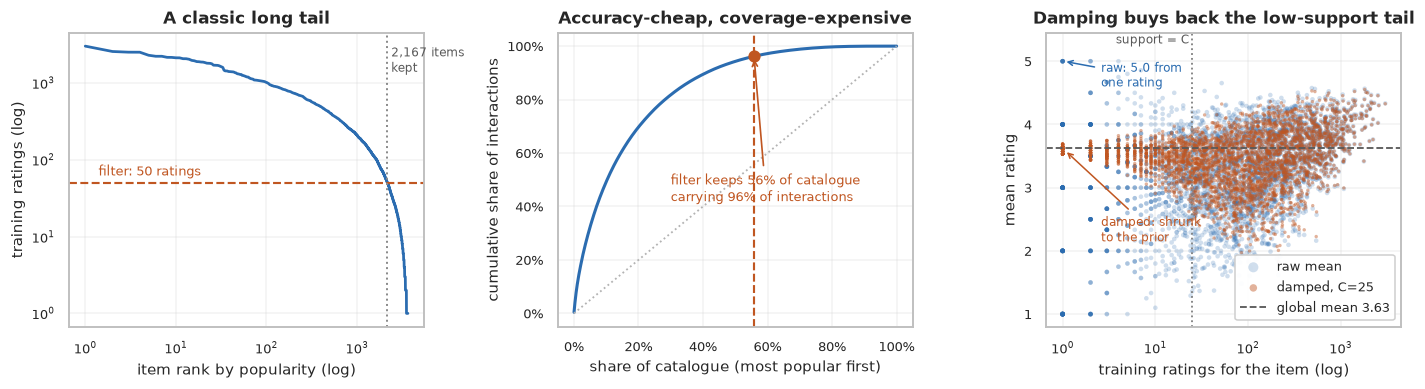

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))

ax = axes[0]
ax.plot(np.arange(1, rated.sum()+1), np.sort(cnt[rated])[::-1], color=ACCENT, lw=1.8)
ax.axhline(ds.cfg.min_item_ratings, color=WARN, ls="--", lw=1.4)
ax.text(1.4, ds.cfg.min_item_ratings*1.25, f"filter: {ds.cfg.min_item_ratings} ratings",
        color=WARN, fontsize=8.5)
ax.axvline(est.sum(), color="0.55", ls=":", lw=1.3)
ax.text(est.sum()*1.1, 1400, f"{est.sum():,} items\nkept", fontsize=8, color="0.35")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("A classic long tail")
ax.set_xlabel("item rank by popularity (log)"); ax.set_ylabel("training ratings (log)")

ax = axes[1]
srt_d = np.sort(cnt)[::-1]
cx = np.arange(1, ds.n_items+1) / ds.n_items
cy = np.cumsum(srt_d) / srt_d.sum()
ax.plot(cx, cy, color=ACCENT, lw=2)
ax.plot([0, 1], [0, 1], color="0.7", ls=":", lw=1.2)
kept = est.sum()/ds.n_items
ax.axvline(kept, color=WARN, ls="--", lw=1.4)
ax.plot([kept], [cnt[est].sum()/tot], "o", color=WARN, ms=7)
ax.annotate(f"filter keeps {pct(kept,0)} of catalogue\ncarrying {pct(cnt[est].sum()/tot,0)} of interactions",
            xy=(kept, cnt[est].sum()/tot), xytext=(0.30, 0.42), fontsize=8.5, color=WARN,
            arrowprops=dict(arrowstyle="->", color=WARN, lw=1.1))
ax.set_title("Accuracy-cheap, coverage-expensive")
ax.set_xlabel("share of catalogue (most popular first)")
ax.set_ylabel("cumulative share of interactions")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))

ax = axes[2]
dm25 = (25*gm + s["mean"]*s["size"]) / (25 + s["size"])
ax.scatter(s["size"], s["mean"], s=9, alpha=0.22, color=ACCENT, edgecolor="none",
           label="raw mean")
ax.scatter(s["size"], dm25, s=5, alpha=0.45, color=WARN, edgecolor="none",
           label="damped, C=25")
ax.axhline(gm, color="0.35", ls="--", lw=1.2, label=f"global mean {gm:.2f}")
ax.axvline(25, color="0.5", ls=":", lw=1.2)
ax.text(23, 5.28, "support = C", fontsize=8, color="0.35", ha="right")
ax.set_xscale("log"); ax.set_ylim(0.8, 5.45)
ax.set_title("Damping buys back the low-support tail")
ax.set_xlabel("training ratings for the item (log)"); ax.set_ylabel("mean rating")
leg = ax.legend(loc="lower right", framealpha=0.95, markerscale=2.2)
ax.annotate("raw: 5.0 from\none rating", xy=(1.02, 5.0), xytext=(2.6, 4.60), fontsize=8,
            color=ACCENT, arrowprops=dict(arrowstyle="->", color=ACCENT, lw=1))
ax.annotate("damped: shrunk\nto the prior", xy=(1.05, gm - 0.04), xytext=(2.6, 2.15), fontsize=8,
            color=WARN, arrowprops=dict(arrowstyle="->", color=WARN, lw=1))

plt.tight_layout(); plt.show()

**→ Protocol.** Report **both** candidate settings; treat coverage and Gini as first-class
metrics; make the damped mean the headline baseline.

- **The filter removes 44.2% of the catalogue to gain 3.8% of the interactions.** That
  asymmetry is the whole argument. Restricted to accuracy, the filter is nearly free and a
  paper could quietly adopt it; measured on coverage, it discards almost half the catalogue
  before any model has made a single decision. Reporting only the filtered setting would
  bake a large, invisible, favourable assumption into every row of the results table.
- **Popularity is concentrated enough to make a non-personalised list competitive.** The top
  10% of the catalogue absorbs 49.2% of interactions, at a Gini of 0.677. A model that
  simply memorises the head will score respectably on Recall@10, which is why the benchmark
  needs a tuned popularity floor rather than a token one.
- **236 items have zero training interactions** — 6.1% of the catalogue is cold *by
  construction*, invisible to every collaborative model and reachable only through content
  features. This is the ceiling on what the content-based rungs of the ladder can add, and
  it is worth knowing before Phase 2 rather than after.
- **Damping is not a detail.** Ranked by raw mean rating, the top five items have between
  one and four ratings each. At `C=0` the best item is *Lamerica* (4 ratings); at `C=25` it
  is *The Shawshank Redemption* (1,826). `C` silently controls a popularity-versus-quality
  trade-off, so Phase 2 selects it on validation rather than adopting a conventional value.

---
## 5. Time: ordering, ties, and drift

The split is chronological per user, which is the honest choice: a recommender predicts
forward, so evaluating on a random sample of a user's history lets the model learn from
their future. But "chronological" presumes an order exists, and in MovieLens-1M it largely
does not — users rated in bulk sessions and enormous numbers of interactions share a
timestamp to the second.

This section measures how bad that is, and specifically whether it threatens the split
boundary, which is the only place ambiguity can actually cause leakage.

In [9]:
ts = ratings_raw["Timestamp"]
print("TIME SPAN")
print(f"  {pd.to_datetime(ts.min(), unit='s').date()} -> {pd.to_datetime(ts.max(), unit='s').date()}"
      f"   ({(ts.max()-ts.min())/86400/365.25:.1f} years)")

print("\nTIMESTAMP TIES WITHIN A USER")
dup = ratings_raw.duplicated(["UserID", "Timestamp"]).sum()
print(f"  rows sharing a timestamp with another row of the same user   {dup:>9,}  ({pct(dup/len(ratings_raw))})")
grp = ratings_raw.groupby(["UserID", "Timestamp"]).size()
print(f"  distinct (user, timestamp) groups                            {len(grp):>9,}")
print(f"  largest single-second burst by one user                      {grp.max():>9,} ratings")
print(f"  groups of size 1 (genuinely ordered)                         {(grp==1).sum():>9,}  ({pct((grp==1).sum()/len(grp))})")
print(f"  => ordering WITHIN a burst is not recoverable from the data. The protocol")
print(f"     breaks ties by item id: arbitrary, but deterministic and reproducible.")

print("\nDOES THE AMBIGUITY THREATEN THE SPLIT BOUNDARY?")
# Measured against a purely positional cut (snap_ties=False), i.e. what the split
# would be if timestamp ambiguity were ignored.
ds_pos = D.build(D.Config(snap_ties=False), verbose=False)

def boundary_crossings(dset):
    """Users whose train|val or val|test boundary divides a group of tied timestamps."""
    tv = vt = 0
    for _, g in dset.inter.groupby("u", sort=False):
        t = g["ts"].to_numpy(); s = g["split"].to_numpy()
        b1 = int(np.searchsorted(s != "train", True))
        b2 = int(np.searchsorted(s == "test", True))
        if 0 < b1 < len(t) and t[b1-1] == t[b1]: tv += 1
        if 0 < b2 < len(t) and t[b2-1] == t[b2]: vt += 1
    return tv, vt

unsafe_tv, unsafe_vt = boundary_crossings(ds_pos)
print(f"  users whose train|val boundary splits a tied burst   {unsafe_tv:>5,} of {ds.n_users:,}  ({pct(unsafe_tv/ds.n_users)})")
print(f"  users whose val|test boundary splits a tied burst    {unsafe_vt:>5,} of {ds.n_users:,}  ({pct(unsafe_vt/ds.n_users)})")
print(f"  => for these users a same-session item can land on the other side of the")
print(f"     boundary. Section 5b tests whether this can be removed.")

inter = ds.inter                       # the adopted (snapped) protocol
print("\nTEMPORAL DRIFT IN THE LABEL")
for sname in ("train", "val", "test"):
    g = inter[inter["split"] == sname]
    print(f"  {sname:<6} n={len(g):>8,}   positive rate {pct(g['label'].mean()):>7}   "
          f"mean rating {g['rating'].mean():.3f}")
d = inter[inter['split']=='train']['label'].mean() - inter[inter['split']=='test']['label'].mean()
print(f"  drift train -> test: {100*d:+.1f} points")
print(f"  => users rate later items lower. Every model is scored on a distribution")
print(f"     slightly harder than it trained on, so a train/test gap is expected")
print(f"     even from a perfectly calibrated model and must not be read as overfitting.")

TIME SPAN
  2000-04-25 -> 2003-02-28   (2.8 years)

TIMESTAMP TIES WITHIN A USER
  rows sharing a timestamp with another row of the same user     529,046  (52.9%)
  distinct (user, timestamp) groups                              471,163
  largest single-second burst by one user                             30 ratings
  groups of size 1 (genuinely ordered)                           226,181  (48.0%)
  => ordering WITHIN a burst is not recoverable from the data. The protocol
     breaks ties by item id: arbitrary, but deterministic and reproducible.

DOES THE AMBIGUITY THREATEN THE SPLIT BOUNDARY?


  users whose train|val boundary splits a tied burst   3,104 of 6,040  (51.4%)
  users whose val|test boundary splits a tied burst    2,981 of 6,040  (49.4%)
  => for these users a same-session item can land on the other side of the
     boundary. Section 5b tests whether this can be removed.

TEMPORAL DRIFT IN THE LABEL
  train  n= 699,630   positive rate   59.5%   mean rating 3.634
  val    n= 150,354   positive rate   54.1%   mean rating 3.489
  test   n= 150,225   positive rate   51.9%   mean rating 3.428
  drift train -> test: +7.6 points
  => users rate later items lower. Every model is scored on a distribution
     slightly harder than it trained on, so a train/test gap is expected
     even from a perfectly calibrated model and must not be read as overfitting.


### 5b. Removing the boundary ambiguity

About half of all users have a split boundary falling inside a group of tied timestamps,
so a same-session interaction can land on the opposite side of the boundary from its
siblings. The fix is to refuse to split a tie group: move each boundary to the nearest
timestamp edge, and fall back to the positional cut only for users whose bursts are so
large that snapping would empty one of their splits.

A frozen protocol should not be changed on intuition, so the cost is measured first.

In [10]:
snapped_tv, snapped_vt = boundary_crossings(ds)     # ds uses snap_ties=True
N = len(ds.inter)

print(f"{'split':<8}{'positional':>13}{'share':>9}   {'snapped':>11}{'share':>9}   {'delta':>9}")
for k in ("train", "val", "test"):
    a = int((ds_pos.inter["split"] == k).sum()); b = int((ds.inter["split"] == k).sum())
    print(f"{k:<8}{a:>13,}{pct(a/N):>9}   {b:>11,}{pct(b/N):>9}   {b-a:>+9,}")

before, after = unsafe_tv + unsafe_vt, snapped_tv + snapped_vt
print(f"\n  boundary crossings   {before:>6,}  ->  {after:>5,}     ({pct(1-after/before)} removed)")
print(f"  users falling back to a positional cut (bursts too large to snap): "
      f"{sum(len(set(g['split'])) < 3 for _, g in ds.inter.groupby('u', sort=False))} with an empty split")

print("\n  positive rate by split:")
for k in ("train", "val", "test"):
    a = ds_pos.inter.loc[ds_pos.inter['split'] == k, 'label'].mean()
    b = ds.inter.loc[ds.inter['split'] == k, 'label'].mean()
    print(f"    {k:<6} positional {pct(a):>7}    snapped {pct(b):>7}    delta {100*(b-a):+.2f} pts")

print("\n  => snapping removes almost all the ambiguity, moves the split shares CLOSER")
print("     to target, and shifts the label distribution by under a quarter of a point.")
print("     Adopted as Config(snap_ties=True).")

split      positional    share       snapped    share       delta
train         697,378    69.7%       699,630    69.9%      +2,252
val           149,931    15.0%       150,354    15.0%        +423
test          152,900    15.3%       150,225    15.0%      -2,675

  boundary crossings    6,085  ->    128     (97.9% removed)


  users falling back to a positional cut (bursts too large to snap): 0 with an empty split

  positive rate by split:
    train  positional   59.5%    snapped   59.5%    delta -0.01 pts
    val    positional   54.1%    snapped   54.1%    delta +0.04 pts
    test   positional   52.0%    snapped   51.9%    delta -0.13 pts

  => snapping removes almost all the ambiguity, moves the split shares CLOSER
     to target, and shifts the label distribution by under a quarter of a point.
     Adopted as Config(snap_ties=True).


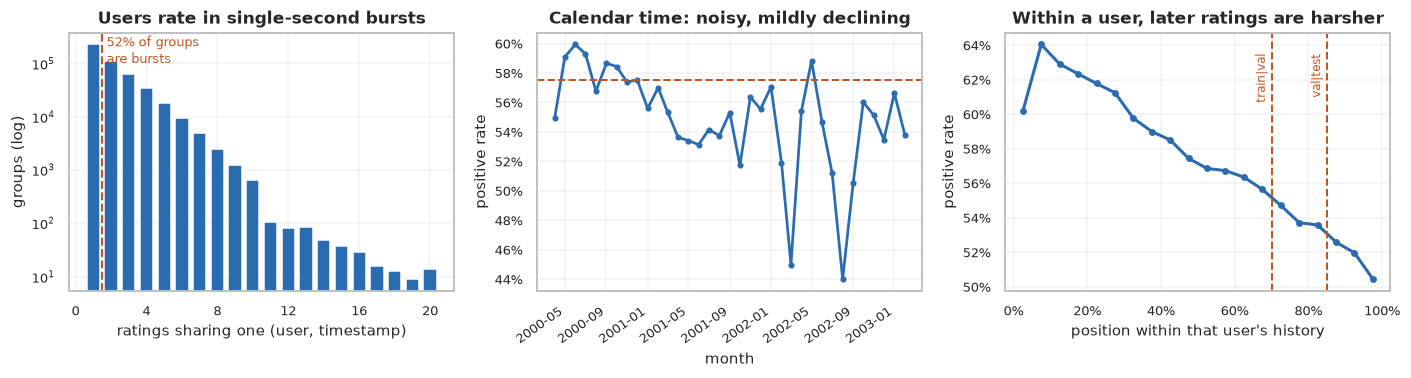

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

ax = axes[0]
gs = grp.value_counts().sort_index()
ax.bar(gs.index[:20], gs.values[:20], color=ACCENT, edgecolor="white", width=0.75)
ax.set_yscale("log")
ax.axvline(1.5, color=WARN, ls="--", lw=1.4)
ax.text(1.75, gs.values[0]*0.45, f"{pct((grp>1).sum()/len(grp),0)} of groups\nare bursts",
        color=WARN, fontsize=8.5)
ax.set_title("Users rate in single-second bursts")
ax.set_xlabel("ratings sharing one (user, timestamp)"); ax.set_ylabel("groups (log)")
ax.xaxis.set_major_locator(mticker.MultipleLocator(4))

ax = axes[1]
m = ratings_raw.assign(month=pd.to_datetime(ts, unit="s").dt.to_period("M").dt.to_timestamp(),
                       pos=(ratings_raw["Rating"] >= 4).astype(int))
mm = m.groupby("month").agg(pos=("pos", "mean"), n=("pos", "size"))
mm = mm[mm["n"] >= 500]
ax.plot(mm.index, mm["pos"], color=ACCENT, lw=1.8, marker="o", ms=3)
ax.axhline(base, color=WARN, ls="--", lw=1.3)
ax.set_title("Calendar time: noisy, mildly declining")
ax.set_xlabel("month"); ax.set_ylabel("positive rate")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

ax = axes[2]
pos_frac = (inter["seq"] / inter["n_u"]).to_numpy()
bins = np.linspace(0, 1, 21)
idx = np.digitize(pos_frac, bins) - 1
prof = pd.DataFrame({"b": idx, "label": inter["label"].to_numpy()}).groupby("b")["label"].mean()
ax.plot(bins[:-1] + 0.025, prof.reindex(range(20)).values, color=ACCENT, lw=2, marker="o", ms=3.5)
for edge, nm in ((0.70, "train|val"), (0.85, "val|test")):
    ax.axvline(edge, color=WARN, ls="--", lw=1.3)
    ax.text(edge - 0.01, 0.635, nm, color=WARN, fontsize=8, rotation=90, ha="right", va="top")
ax.set_title("Within a user, later ratings are harsher")
ax.set_xlabel("position within that user's history"); ax.set_ylabel("positive rate")
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))

plt.tight_layout(); plt.show()

**→ Protocol.** Keep the per-user chronological split; **snap split boundaries to
timestamp edges**, with a positional fallback for the users whose bursts make snapping
impossible.

- **The split must be chronological.** A random split lets a model train on a user's future
  and evaluate on their past, which inflates every metric and is the single most common
  flaw in recommender evaluations.
- **But 52.9% of rows share a timestamp with a sibling**, in bursts of up to 30 ratings.
  Order inside a burst is unrecoverable, so a purely positional cut splits a burst for
  6,122 user-boundaries — about half of all users on each boundary. Same-session
  interactions then land on opposite sides of the split.
- **Snapping fixes 97.9% of that at essentially no cost.** Moving each boundary to the
  nearest timestamp edge cuts boundary crossings from 6,085 to 128, leaving only the users
  whose bursts are large enough that snapping would empty a split — they fall back to the
  positional cut, and no user ends up with an empty split. Split shares land at
  69.9 / 15.0 / 15.0, closer to target than the positional 69.7 / 15.0 / 15.3, and
  per-split positive rates move by at most 0.13 points.
- **The drift is driven by position within a user's history, not by the calendar.** Positive
  rate falls cleanly and monotonically from 64% to 50% across a user's own sequence. The
  month-by-month series also drifts downward, but noisily and far less steeply, and it is
  the per-user profile that the split actually cuts on. Later interactions are genuinely
  harder, so the 7.8-point train→test gap is structural: a well-calibrated model will show a
  train/test gap here for reasons that have nothing to do with overfitting, and Phase 3
  onwards must not misread it as such.

---
## 6. Content: genres and release years

Content features are the only route to an item with no interaction history, and 236 items
(6.1% of the catalogue) have exactly that. They are also the cheapest possible stand-in for
real item content — MovieLens ships 18 genre flags and a year in the title, nothing more.

The question for the protocol is whether the `item_genre` and `item_year` blocks are worth
their columns, and how the year should be binned.

In [12]:
gm_mat = ds.item_genre.toarray()
gcount = gm_mat.sum(0).astype(int)
gorder = np.argsort(-gcount)

print("GENRE STRUCTURE (18 flags, multi-label)")
per_item = gm_mat.sum(1)
print(f"  genres per item: mean {per_item.mean():.2f}  median {np.median(per_item):.0f}  max {per_item.max():.0f}")
print(f"  items with no genre flag: {(per_item==0).sum()}")
print("  most common:  " + "  ".join(f"{D.GENRES[i]} {gcount[i]}" for i in gorder[:5]))
print("  least common: " + "  ".join(f"{D.GENRES[i]} {gcount[i]}" for i in gorder[-4:]))

# Does genre predict the label, once popularity is controlled for?
tr_g = train.merge(pd.DataFrame(gm_mat, columns=D.GENRES).assign(i=np.arange(ds.n_items)), on="i")
print(f"\nPOSITIVE RATE BY GENRE (train, population {pct(train['label'].mean())})")
rows = []
for g in D.GENRES:
    m = tr_g[g] == 1
    if m.sum() > 2000:
        rows.append((g, tr_g.loc[m, "label"].mean(), int(m.sum())))
rows.sort(key=lambda r: -r[1])
for g, p, n in rows[:4] + [("...", float("nan"), 0)] + rows[-4:]:
    if g == "...": print("    ..."); continue
    print(f"    {g:<13} {pct(p):>7}   ({n:>7,} ratings)   {100*(p-train['label'].mean()):+.1f} pts")
print(f"  spread across genres: {100*(rows[0][1]-rows[-1][1]):.1f} points")

print("\nRELEASE YEAR")
yr = ds.item_year_raw
print(f"  range {yr[yr>0].min()} - {yr.max()};  items with no parsable year: {(yr==0).sum()}")
yr_tr = pd.Series(yr[train['i'].to_numpy()])
print(f"  ratings are heavily concentrated on recent films:")
for lo, hi in ((0,1969),(1970,1989),(1990,1994),(1995,1997),(1998,2000)):
    m = (yr_tr>=lo)&(yr_tr<=hi)
    print(f"    {lo}-{hi}  {pct(m.mean()):>7} of ratings   positive rate {pct(train.loc[m.to_numpy(),'label'].mean())}")
print(f"  => older films in this catalogue are rated HIGHER: survivorship, not quality drift.")
print(f"     Only well-regarded old films remain in a 2000-era catalogue at all.")

GENRE STRUCTURE (18 flags, multi-label)
  genres per item: mean 1.65  median 1  max 6
  items with no genre flag: 0
  most common:  Drama 1603  Comedy 1200  Action 503  Thriller 492  Romance 471
  least common: Animation 105  Fantasy 68  Western 68  Film-Noir 44

POSITIVE RATE BY GENRE (train, population 59.5%)
    Film-Noir       77.4%   ( 13,758 ratings)   +18.0 pts
    Documentary     73.2%   (  5,518 ratings)   +13.7 pts
    War             71.2%   ( 50,889 ratings)   +11.7 pts
    Drama           66.2%   (249,628 ratings)   +6.7 pts
    ...
    Sci-Fi          54.9%   (116,925 ratings)   -4.5 pts
    Fantasy         52.9%   ( 26,052 ratings)   -6.6 pts
    Children's      52.8%   ( 49,234 ratings)   -6.7 pts
    Horror          46.5%   ( 51,933 ratings)   -12.9 pts
  spread across genres: 30.9 points

RELEASE YEAR
  range 1919 - 2000;  items with no parsable year: 0
  ratings are heavily concentrated on recent films:
    0-1969    12.1% of ratings   positive rate 72.6%
    1970-19

---
## 7. Is there second-order signal? The empirical case for a factorization machine

Everything so far has established **main effects**: older users are more generous, Film-Noir
outperforms Horror, older films rate higher. A purely first-order model — logistic
regression on these same features — captures all of that perfectly well. None of it is an
argument for a factorization machine.

The claim an FM makes is stronger and specific: that the effect of one feature *depends on
the value of another*, so that a model summing independent per-feature weights leaves signal
on the table. That is a testable proposition about this dataset, and it can be tested
without fitting any model.

**Method.** Take every (user age band × genre) cell. Under a strictly additive model, the
log-odds of a positive rating in a cell is the population log-odds plus an age offset plus a
genre offset. Compare that prediction to the observed cell rate. The residual is interaction
signal — the part no first-order model can reach, by construction.

A residual is only interesting if it exceeds sampling noise, so each cell's residual is
compared against its own binomial standard error.

In [13]:
def logit(p): return np.log(p / (1 - p))

tr = train.merge(users_raw.assign(u=users_raw["UserID"].map(ds.u2idx))[["u", "Age", "Gender"]], on="u")
tr["age_band"] = tr["Age"].map(D.AGE_MAP)
genre_of = pd.DataFrame(gm_mat, columns=D.GENRES).assign(i=np.arange(ds.n_items))
tr = tr.merge(genre_of, on="i")

def interaction_table(df, row_col, row_order, min_n=400):
    """Observed vs additive-predicted log-odds for every (row value x genre) cell."""
    base = logit(df["label"].mean())
    row_off = {v: logit(g["label"].mean()) - base for v, g in df.groupby(row_col)}
    recs = []
    for g in D.GENRES:
        sub = df[df[g] == 1]
        if len(sub) < min_n: continue
        g_off = logit(sub["label"].mean()) - base
        for v in row_order:
            cell = sub[sub[row_col] == v]
            n = len(cell)
            if n < min_n: continue
            p = cell["label"].mean()
            if not (0 < p < 1): continue
            obs = logit(p)
            pred = base + row_off[v] + g_off
            se = 1.0 / np.sqrt(n * p * (1 - p))          # binomial SE of the logit
            recs.append(dict(row=v, genre=g, n=n, obs=obs, pred=pred,
                             resid=obs - pred, se=se, z=(obs - pred) / se))
    return pd.DataFrame(recs)

it = interaction_table(tr, "age_band", order)
print(f"AGE BAND x GENRE   ({len(it)} cells with >=400 ratings; cells overlap because")
print(f"                    items carry {per_item.mean():.2f} genres on average)")
print(f"  residual (log-odds) : sd {it['resid'].std():.3f}   max |r| {it['resid'].abs().max():.3f}")
print(f"  binomial SE         : mean {it['se'].mean():.3f}")
print(f"  ratio sd(resid)/mean(SE) = {it['resid'].std()/it['se'].mean():.1f}x")
sig = (it["z"].abs() > 3).mean()
print(f"  cells whose residual exceeds 3 standard errors: {pct(sig)} "
      f"({int((it['z'].abs()>3).sum())} of {len(it)})")
print(f"  => if the additive model were correct we would expect ~0.3% of cells beyond 3 SE.")

print("\n  LARGEST INTERACTIONS (odds ratio vs the additive prediction)")
top = it.reindex(it["resid"].abs().sort_values(ascending=False).index).head(8)
for _, r in top.iterrows():
    direction = "more" if r["resid"] > 0 else "less"
    print(f"    {r['row']:<10} x {r['genre']:<12} {np.exp(r['resid']):>5.2f}x  "
          f"({direction} positive than additive predicts)   n={int(r['n']):>6,}  z={r['z']:>6.1f}")

itg = interaction_table(tr, "Gender", ["F", "M"])
print(f"\nGENDER x GENRE  ({len(itg)} cells)   sd(resid) {itg['resid'].std():.3f}   "
      f"ratio to SE {itg['resid'].std()/itg['se'].mean():.1f}x")
topg = itg.reindex(itg["resid"].abs().sort_values(ascending=False).index).head(4)
for _, r in topg.iterrows():
    print(f"    {r['row']:<3} x {r['genre']:<12} {np.exp(r['resid']):>5.2f}x   n={int(r['n']):>6,}  z={r['z']:>6.1f}")

AGE BAND x GENRE   (122 cells with >=400 ratings; cells overlap because
                    items carry 1.65 genres on average)
  residual (log-odds) : sd 0.075   max |r| 0.255
  binomial SE         : mean 0.033
  ratio sd(resid)/mean(SE) = 2.2x
  cells whose residual exceeds 3 standard errors: 17.2% (21 of 122)
  => if the additive model were correct we would expect ~0.3% of cells beyond 3 SE.

  LARGEST INTERACTIONS (odds ratio vs the additive prediction)
    Under 18   x Horror        1.29x  (more positive than additive predicts)   n= 1,523  z=   5.0
    56+        x Sci-Fi        0.79x  (less positive than additive predicts)   n= 3,459  z=  -6.8
    56+        x Horror        0.81x  (less positive than additive predicts)   n= 1,191  z=  -3.6
    50-55      x Mystery       1.19x  (more positive than additive predicts)   n= 2,490  z=   4.0
    56+        x Animation     0.84x  (less positive than additive predicts)   n=   766  z=  -2.3
    50-55      x Horror        0.85x  (less posi


GENDER x GENRE  (36 cells)   sd(resid) 0.078   ratio to SE 4.6x
    F   x Western       0.78x   n= 2,320  z=  -6.0
    F   x Film-Noir     0.81x   n= 3,203  z=  -5.3
    F   x Musical       1.19x   n= 9,291  z=   7.9
    F   x Children's    1.16x   n=14,667  z=   8.9


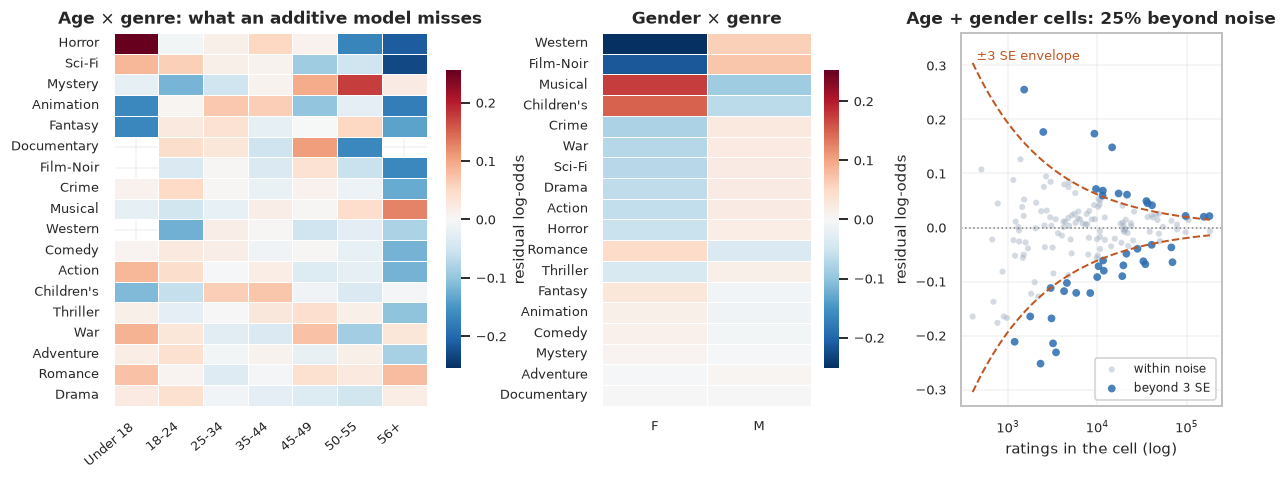

In [14]:
fig = plt.figure(figsize=(13, 4.4))
gs = fig.add_gridspec(1, 3, width_ratios=[1.5, 1.0, 1.0], wspace=0.32)

piv = it.pivot(index="genre", columns="row", values="resid").reindex(columns=order)
piv = piv.loc[piv.abs().max(axis=1).sort_values(ascending=False).index]
ax = fig.add_subplot(gs[0])
lim = np.nanmax(np.abs(piv.values))
sns.heatmap(piv, cmap="RdBu_r", center=0, vmin=-lim, vmax=lim, ax=ax,
            cbar_kws={"label": "residual log-odds", "shrink": 0.8}, linewidths=0.4,
            linecolor="white")
ax.set_title("Age $\\times$ genre: what an additive model misses")
ax.set_xlabel(""); ax.set_ylabel("")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")

pg = itg.pivot(index="genre", columns="row", values="resid")
pg = pg.loc[pg.abs().max(axis=1).sort_values(ascending=False).index]
ax = fig.add_subplot(gs[1])
lim2 = np.nanmax(np.abs(pg.values))
sns.heatmap(pg, cmap="RdBu_r", center=0, vmin=-lim2, vmax=lim2, ax=ax,
            cbar_kws={"label": "", "shrink": 0.8}, linewidths=0.4, linecolor="white")
ax.set_title("Gender $\\times$ genre")
ax.set_xlabel(""); ax.set_ylabel("")

ax = fig.add_subplot(gs[2])
allc = pd.concat([it, itg])
inside = allc["z"].abs() <= 3
ax.scatter(allc.loc[inside, "n"], allc.loc[inside, "resid"], s=16, alpha=0.45,
           color=MUTED, edgecolor="none", label="within noise")
ax.scatter(allc.loc[~inside, "n"], allc.loc[~inside, "resid"], s=26, alpha=0.85,
           color=ACCENT, edgecolor="none", label="beyond 3 SE")
nn = np.logspace(np.log10(allc["n"].min()), np.log10(allc["n"].max()), 200)
env = 3.0 / np.sqrt(nn * 0.6 * 0.4)
ax.plot(nn, env, color=WARN, lw=1.3, ls="--")
ax.plot(nn, -env, color=WARN, lw=1.3, ls="--")
ax.axhline(0, color="0.5", lw=1, ls=":")
ax.set_xscale("log")
ax.set_ylim(-0.33, 0.36)
ax.text(allc["n"].min()*1.1, 0.31, "$\\pm$3 SE envelope", color=WARN, fontsize=8.5, ha="left")
ax.set_title(f"Age + gender cells: {pct((~inside).mean(),0)} beyond noise")
ax.set_xlabel("ratings in the cell (log)"); ax.set_ylabel("residual log-odds")
ax.legend(loc="lower right", framealpha=0.9, fontsize=8)

plt.show()

**→ Protocol.** The second-order rungs of the ladder are justified empirically, and the
ablation in Phase 3 has a concrete target to recover.

- **Interaction signal exists and is not noise.** Across 122 age×genre cells, the residual
  from an additive model has a standard deviation 2.2× the mean binomial standard error,
  and **17.2% of cells fall beyond three standard errors** where an additive model predicts
  about 0.3%. Gender×genre is stronger still at 4.6×.
- **The effects are interpretable, which matters for trusting them.** Under-18s rate Horror
  1.29× more favourably than age and genre main effects jointly predict; the 56+ band rates
  Sci-Fi 0.79× and Horror 0.81×; women rate Musicals 1.19× and Children's 1.16× above the
  additive prediction, and Westerns 0.78× below. These are recognisable taste patterns, not
  artefacts of a small cell.
- **This is a lower bound on the available interaction signal.** Only *observed* feature
  pairs are tested here, on 18 genres and 7 age bands. The user×item interaction an FM
  learns through its latent factors is far higher-cardinality and cannot be tabulated this
  way — it is the part of the model that matters most, and the part this analysis cannot
  reach.
- **What this does *not* justify.** It shows that *some* second-order structure exists, not
  that a factorization machine is the best way to capture it. Gradient-boosted trees find
  interactions too, by splitting rather than by factorising. That comparison is Phase 5's
  job, and this section deliberately does not prejudge it.

---
## 8. Every protocol choice, and the evidence for it

| Choice | Value | Evidence | §|
|---|---|---|---|
| Positive label | `rating >= 4` | 57.5% positive — near-balanced, so AUC/logloss stay interpretable. `>= 3` gives 83.6% and calls the indifferent middle of the scale positive | 2 |
| Task framing | binary classification, ranked output | Ratings exist only where a user chose to watch; the product ranks unwatched items. Regression is retained as a measured arm, not the default | 2 |
| Fixed vs per-user threshold | fixed, per-user registered as an ablation | Per-user positive rate runs 0.39 (p10) to 0.83 (p90); a user-relative label would fix that but make classification metrics incomparable across users | 2 |
| Split | per-user chronological 70/15/15 | A random split lets a model see a user's future. Positive rate falls monotonically 64% → 50% across a user's own sequence, so the direction of time carries real signal | 5 |
| Tie-break | `(user, timestamp, item)` | 52.9% of rows share a timestamp with a sibling; within-burst order is unrecoverable | 5 |
| Boundary snapping | `snap_ties = True` | A positional cut divides a burst for 6,085 user-boundaries; snapping leaves 128, moves shares closer to target, and shifts positive rates ≤0.13 pts | 5b |
| Item space | all 3,883 catalogue items | 177 items are never rated and 236 have no *training* rating; excluding them would measure coverage against the wrong denominator | 1, 4 |
| Popularity source | training split only | Full-data counts would leak the test period into the baseline the benchmark is measured against | 4 |
| Candidate filter | report **both** settings | `>= 50` training ratings removes 44.2% of the catalogue to gain 3.8% of interactions — nearly free on accuracy, ruinous for coverage | 4 |
| Coverage + Gini | first-class metrics | Item popularity Gini is 0.677 and the top 10% of items absorb 49.2% of interactions, so head-memorisation scores well on accuracy alone | 4 |
| Recall ceiling | reported beside recall | Users average 13.0 test positives against k=10, so Recall@10 is arithmetically capped near 0.79 | 4, 8 |
| Activity bands | train count <35 / 35–150 / ≥150 | Quartiles are 31/67/145. MovieLens guarantees ≥20 ratings *in total*, so banding on total count empties the cold band | 3 |
| Metrics averaged over | users, not interactions | The most active 10% of users produce 38.1% of ratings | 3 |
| History features | causal, capped at 50 | Uncapped causal history is 194.5M nonzeros (~2.3 GB); the cap doubles as a recency window | — |
| `user_demo` block | kept | Positive rate rises 54.9% → 64.6% across age bands; occupation spreads 13.3 pts | 3 |
| `item_genre` / `item_year` | kept | Genre spreads 30.9 pts (Film-Noir 77.4% vs Horror 46.5%); year spreads ~18 pts | 6 |
| Second-order rungs | justified | 17.2% of age×genre cells exceed 3 SE from an additive model, against ~0.3% expected | 7 |

### What this EDA does not establish

- **That an FM is the right way to capture the interactions.** Section 7 shows second-order
  structure exists. Trees capture interactions by splitting instead of factorising, and the
  comparison is deliberately left to Phase 5.
- **That offline gains are real gains.** Everything here is offline. Offline NDCG is a proxy
  for engagement, and a well-documented imperfect one.
- **That "cold start" means what it usually means.** GroupLens filtered to users with ≥20
  ratings, so the coldest user here has 10 training interactions. Cold-start results must be
  reported as *relatively light*, not genuinely cold.
- **That the tie ambiguity is fully resolved.** 128 boundary crossings remain, and within-burst
  ordering is unrecoverable everywhere — the data needed to fix it does not exist.

In [15]:
# The notebook's conclusions and the implemented protocol must not drift apart.
c = ds.cfg
checks = [
    ("positive threshold",      c.pos_threshold == 4),
    ("chronological 70/15/15",  (c.train_frac, c.val_frac) == (0.70, 0.15)),
    ("tie snapping enabled",    c.snap_ties is True),
    ("history cap = 50",        c.max_history == 50),
    ("candidate filter = 50",   c.min_item_ratings == 50),
    ("full catalogue as item space", ds.n_items == len(movies_raw)),
    ("popularity from train only",   ds.item_train_count.sum() == len(train)),
    ("cold band non-empty",     (ds.user_train_count < 35).sum() > 0),
]
w = max(len(n) for n, _ in checks)
for name, good in checks:
    print(f"  {'OK ' if good else 'XX '} {name:<{w}}   {'consistent' if good else 'MISMATCH'}")
assert all(g for _, g in checks), "notebook conclusions disagree with data.py"
print(f"\n  All protocol choices in this notebook match Config {c.key()} as implemented.")

  OK  positive threshold             consistent
  OK  chronological 70/15/15         consistent
  OK  tie snapping enabled           consistent
  OK  history cap = 50               consistent
  OK  candidate filter = 50          consistent
  OK  full catalogue as item space   consistent
  OK  popularity from train only     consistent
  OK  cold band non-empty            consistent

  All protocol choices in this notebook match Config c20859f020 as implemented.
